# 04 · Feature library, availability and quality

Stage 2 · part 1. This notebook (a) settles the forecast-origin convention, (b) corrects the Stage 1
temperature statement, (c) builds the candidate feature library and its availability manifest, and
(d) runs the automated quality and redundancy analysis.

**Locked test year.** Only `load_development_panel()` is used (2016–2024). 2025 rows are dropped on load.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
import time, resource
from dengueshield.data import load_development_panel, WEATHER
from dengueshield.features import FeaturePipeline
from dengueshield.evaluation.folds import fold_data, dev_folds, CONVENTIONS
from dengueshield.evaluation import quality as q

OUT = ROOT / "reports/features"; FIG = OUT / "figures"; TAB = OUT / "tables"
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_development_panel()
assert panel.date.dt.year.max() == 2024
S = {}
print(len(panel), panel.date.min().date(), panel.date.max().date())

28200 2016-01-04 2024-12-30


## 1. Forecast-origin convention: what does the weekly date label mean?

The CSV carries one Monday date per week. Whether row *t* describes the week starting on *t* or ending on *t*
decides whether week-*t* weather is available to a forecast made "at *t*".

**Evidence from the data.** The monsoon/dry regime flips at week boundaries. If the generator assigned a week to a
month by the Monday date, the week of 2020-09-28 would be wet; it is dry, while 2021-09-27 is wet. Assigning each
week to the month of its **midpoint** (Monday + 3 days, i.e. ISO-week semantics) removes these contradictions.
That is what a week-**start** label would produce. A week-**end** label would put the midpoint three days *before* the date.
This is strong circumstantial evidence, not proof: the file has no metadata.

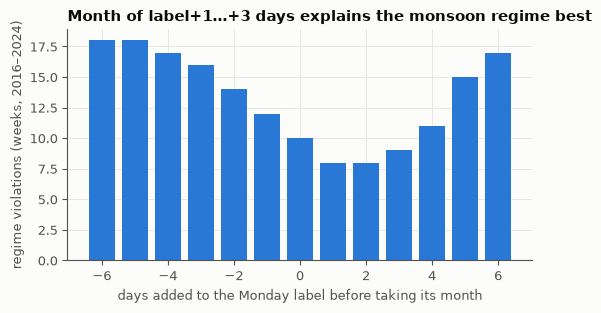

,6,7,8,9,10,11,12,13
date,2019-09-23,2019-09-30,2020-09-21,2020-09-28,2020-10-05,2021-09-20,2021-09-27,2021-10-04
weekday,Monday,Monday,Monday,Monday,Monday,Monday,Monday,Monday
iso_week,39,40,39,40,41,38,39,40
mean_rain_mm,54.0,2.4,204.9,2.4,2.5,90.6,121.5,2.3
wet,True,False,True,False,False,True,True,False


{'best_offsets_days': [1, 2, 3],
 'violations_offset0': 10,
 'violations_best': 8}

In [2]:
nat = panel.groupby("date").rainfall_mm.mean(); wet = (nat > 30).to_numpy()
rows = []
for k in range(-6, 7):
    m = (nat.index + pd.Timedelta(days=k)).month
    bad = (np.isin(m, [6, 7, 8, 9]) & ~wet) | (np.isin(m, [10, 11, 12, 1, 2, 3]) & wet)
    rows.append({"offset_days_added_to_label": k, "regime_violations": int(bad.sum())})
ev = pd.DataFrame(rows); ev.to_csv(TAB / "date_convention_evidence.csv", index=False)
boundary = []
for y in range(2016, 2025):
    s = nat[(nat.index >= f"{y}-09-20") & (nat.index <= f"{y}-10-06")]
    boundary += [{"date": d.date(), "weekday": d.day_name(), "iso_week": int(d.isocalendar().week), "mean_rain_mm": round(float(v), 1), "wet": bool(v > 30)} for d, v in s.items()]
boundary = pd.DataFrame(boundary); boundary.to_csv(TAB / "september_boundary_weeks.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(ev.offset_days_added_to_label, ev.regime_violations, color=SERIES[0])
ax.set_xlabel("days added to the Monday label before taking its month"); ax.set_ylabel("regime violations (weeks, 2016–2024)")
ax.set_title("Month of label+1…+3 days explains the monsoon regime best")
save(fig, "01_date_convention_evidence")
S["date_convention"] = {"best_offsets_days": ev.sort_values("regime_violations").offset_days_added_to_label.head(3).tolist(),
                        "violations_offset0": int(ev.loc[ev.offset_days_added_to_label == 0, "regime_violations"].iloc[0]),
                        "violations_best": int(ev.regime_violations.min())}
display(boundary[boundary.date.astype(str).str[:4].isin(["2019", "2020", "2021"])].T.iloc[:, :14])
S["date_convention"]

### Operational consequence

Two origin conventions are implemented as availability lags (`wlag` for weather, `clag` for cases):

| Convention | Meaning | Latest usable weather | Latest usable cases | Calendar lead to the start of target week *t+h* |
|---|---|---|---|---|
| **A · end of week** (`wlag=0, clag=0`) | forecast issued after week *t* closes | week *t* | week *t* | *h − 1* weeks |
| **B · start of week** (`wlag=1, clag=1`) | issued Monday morning of week *t* | week *t−1* | week *t−1* | *h* weeks |
| **C · case delay** (`wlag=0, clag=1`) | A with one-week reporting delay for cases | week *t* | week *t−1* | *h − 1* weeks |

Stage 1 used convention A, so **A is the primary convention for like-for-like comparison with the Stage 1 targets**.
Because the label evidence points to week-start semantics, **B is the conservative operational convention** and every
selected configuration is re-evaluated under B and C.

## 2. Correction: maximum and minimum temperature are not exact copies of the average

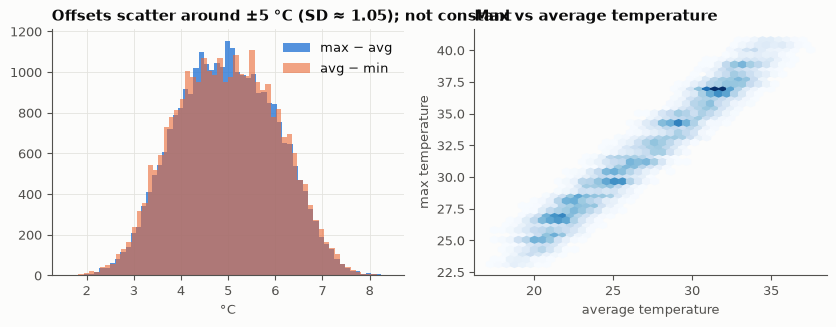

,corr_with_avg,R2_given_avg,offset_mean,offset_sd,offset_min,offset_max,residual_sd_C,n_distinct_offsets,corr_of_offsets,range_mean,range_sd
max_temp_c,0.9733,0.9472,4.9761,1.0378,1.72,8.36,1.0353,600.0,NaN,NaN,NaN
min_temp_c,0.9718,0.9445,-4.9681,1.0625,-8.39,-1.60,1.0586,603.0,NaN,NaN,NaN
max_vs_min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.341,9.9442,1.2058


In [3]:
t = panel[["avg_temp_c", "max_temp_c", "min_temp_c"]]
rows = {}
for c in ("max_temp_c", "min_temp_c"):
    slope, icpt = np.polyfit(t.avg_temp_c, t[c], 1)
    resid = t[c] - (slope * t.avg_temp_c + icpt)
    off = t[c] - t.avg_temp_c
    rows[c] = {"corr_with_avg": t[c].corr(t.avg_temp_c), "R2_given_avg": 1 - resid.var() / t[c].var(),
               "offset_mean": off.mean(), "offset_sd": off.std(), "offset_min": off.min(), "offset_max": off.max(),
               "residual_sd_C": resid.std(), "n_distinct_offsets": int(off.round(2).nunique())}
rows["max_vs_min"] = {"corr_of_offsets": (t.max_temp_c - t.avg_temp_c).corr(t.avg_temp_c - t.min_temp_c),
                      "range_mean": (t.max_temp_c - t.min_temp_c).mean(), "range_sd": (t.max_temp_c - t.min_temp_c).std()}
red = pd.DataFrame(rows).T; red.to_csv(TAB / "temperature_redundancy.csv"); S["temperature_redundancy"] = red.round(4).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(t.max_temp_c - t.avg_temp_c, bins=60, color=SERIES[0], alpha=0.8, label="max − avg"); ax[0].hist(t.avg_temp_c - t.min_temp_c, bins=60, color=SERIES[1], alpha=0.6, label="avg − min")
ax[0].legend(); ax[0].set_title("Offsets scatter around ±5 °C (SD ≈ 1.05); not constant"); ax[0].set_xlabel("°C")
ax[1].hexbin(t.avg_temp_c, t.max_temp_c, gridsize=40, cmap="Blues", mincnt=1); ax[1].set_xlabel("average temperature"); ax[1].set_ylabel("max temperature")
ax[1].set_title("Max vs average temperature"); ax[1].grid(False)
save(fig, "02_temperature_redundancy")
red.round(4)

**Correction to Stage 1.** Stage 1 described max/min temperature as "avg ± ~5 °C". The accurate statement is:
`max − avg` and `avg − min` each average ≈ 4.97 °C with SD ≈ 1.05 °C (hundreds of distinct values), the two offsets are
negatively correlated (≈ −0.34), and each of max/min is predictable from the average with R² ≈ 0.94–0.95. They are **highly redundant but
not deterministic duplicates**; their incremental predictive value is measured in the ablation (notebook 05,
`inc_temp_no_maxmin` vs `inc_temp`, `inc_maxmin_only`) instead of being discarded in advance.

## 3. Build the candidate library and availability manifest

In [4]:
fold = dev_folds()[0]
mans = {}
for h in (2, 3, 4):
    fd = fold_data(panel, "A_end_of_week", fold, h)
    mans[h] = fd.manifest
man = mans[3][["feature", "family", "subfamily", "description"]].copy()
for h in (2, 3, 4):
    man[f"avail_A_h{h}"] = mans[h].availability_class.to_numpy()
for h in (2, 3, 4):   # convention B availability
    man[f"avail_B_h{h}"] = fold_data(panel, "B_start_of_week", fold, h).manifest.availability_class.to_numpy()
LABEL = {1: "1 observed at origin", 2: "2 derived from observed history", 3: "3 known in advance", 4: "4 climatology estimate", 5: "5 prohibited"}
man.to_csv(OUT / "feature_manifest.csv", index=False)
S["n_candidate_features"] = len(man)
print("candidate features:", len(man))
fam = man.groupby("family").agg(n=("feature", "size")).join(
    pd.concat({f"A_h{h}": man.groupby("family")[f"avail_A_h{h}"].agg(lambda s: dict(sorted(s.value_counts().items()))) for h in (2, 3, 4)}, axis=1))
fam.to_csv(TAB / "family_availability.csv"); fam

candidate features: 204


,n,A_h2,A_h3,A_h4
family,,,,
breeding,7,{2: 7},{2: 7},{2: 7}
calendar,14,{3: 14},{3: 14},{3: 14}
case,37,{2: 37},{2: 37},{2: 37}
climate_int,6,{2: 6},{2: 6},{2: 6}
hist,8,"{2: 3, 4: 5}","{2: 3, 4: 5}","{2: 3, 4: 5}"
humidity,15,"{1: 2, 2: 12, 3: 1}","{1: 1, 2: 12, 3: 1, 4: 1}","{1: 1, 2: 12, 3: 1, 4: 1}"
rain_align,20,"{1: 1, 2: 8, 3: 5, 4: 6}","{1: 1, 2: 6, 3: 5, 4: 8}","{1: 1, 2: 5, 3: 5, 4: 9}"
rain_lag,11,"{1: 1, 2: 10}","{1: 1, 2: 10}","{1: 1, 2: 10}"
rain_roll,35,{2: 35},{2: 35},{2: 35}


In [5]:
cnt = pd.concat({f"A h={h}": man[f"avail_A_h{h}"].map(LABEL).value_counts() for h in (2, 3, 4)} |
                {f"B h={h}": man[f"avail_B_h{h}"].map(LABEL).value_counts() for h in (2, 3, 4)}, axis=1).fillna(0).astype(int)
cnt.loc["5 prohibited (never built)"] = 0
cnt.to_csv(TAB / "availability_class_counts.csv"); cnt

,A h=2,A h=3,A h=4,B h=2,B h=3,B h=4
2 derived from observed history,153,151,150,151,150,149
3 known in advance,30,30,30,30,30,30
4 climatology estimate,13,16,17,16,17,18
1 observed at origin,8,7,7,7,7,7
5 prohibited (never built),0,0,0,0,0,0


Class 5 (prohibited) features are **never constructed**: observed weather after the origin, observed cases after the origin,
and the Stage 1 oracle inputs. `PROHIBITED` in `dengueshield.features.families` lists them, and the pipeline refuses to emit
those names. The Stage 1 `oracle_weather_glm` stays an oracle diagnostic and is excluded from every deployable comparison below.

## 4. Quality and redundancy analysis (fold 2022 training rows, h = 3, convention A)

In [6]:
fd = fold_data(panel, "A_end_of_week", fold, 3)
tr = fd.train.to_numpy(); Xtr = fd.X[tr]; ytr = fd.meta.y_true[tr].to_numpy()
prof = q.profile(Xtr).merge(man[["feature", "family"]], on="feature"); prof.to_csv(TAB / "feature_profile_fold2022_h3.csv", index=False)
S["quality"] = {"features_with_missing_gt_20pct": prof[prof.missing_frac > 0.2].feature.tolist(),
                "constant": prof[prof.constant].feature.tolist(), "near_constant": prof[prof.near_constant & ~prof.constant].feature.tolist(),
                "max_robust_z_gt_20": prof[prof.max_robust_z > 20].feature.tolist()}
prof.sort_values("missing_frac", ascending=False).head(12)[["feature", "family", "missing_frac"]]

,feature,family,missing_frac
77,rain_clim_wetcond_tl3,rain_align,0.543011
78,rain_clim_drycond_tl3,rain_align,0.436559
120,rh_anom_mean4,humidity,0.170968
100,temp_anom_mean4,temp,0.170968
198,hist_rain_anom4,hist,0.170968
196,hist_cases_52w,hist,0.164516
75,rain_clim_sd_tl3,rain_align,0.164516
119,rh_anom0,humidity,0.161290
76,rain_pwet_tl3,rain_align,0.161290
74,rain_clim_tl3,rain_align,0.161290


In [7]:
dup = pd.concat({f"{c[0]}|h{h}": q.duplicates(fold_data(panel, c, fold, h).X[fold_data(panel, c, fold, h).train.to_numpy()])
                 for c in ("A_end_of_week", "B_start_of_week") for h in (2, 3, 4)}, names=["setting"]).reset_index(level=0)
dup.to_csv(TAB / "duplicate_features_by_setting.csv", index=False)
always = set.intersection(*[set(g.duplicate) for _, g in dup.groupby("setting")])
S["duplicates_in_every_setting"] = sorted(always)
print(len(always), "features are exact/rescaled copies in all six settings:", sorted(always))
dup.groupby("setting").size()

19 features are exact/rescaled copies in all six settings: ['breed_no_wl', 'breed_rain_only', 'rain_mean2', 'rain_mean3', 'rain_mean4', 'rain_mean6', 'rain_mean8', 'rain_tl2_obs', 'rain_tl3_obs', 'rain_tl4_obs', 'rain_tl5', 'rain_tl5_obs', 'rain_win_nobs', 'rh_tl2_obs', 'temp_tl6', 'temp_tl6_obs', 'temp_tl7_obs', 'temp_tl8_obs', 'vuln_wl_x_ewm3']


setting
A|h2    24
A|h3    22
A|h4    22
B|h2    22
B|h3    22
B|h4    21
dtype: int64

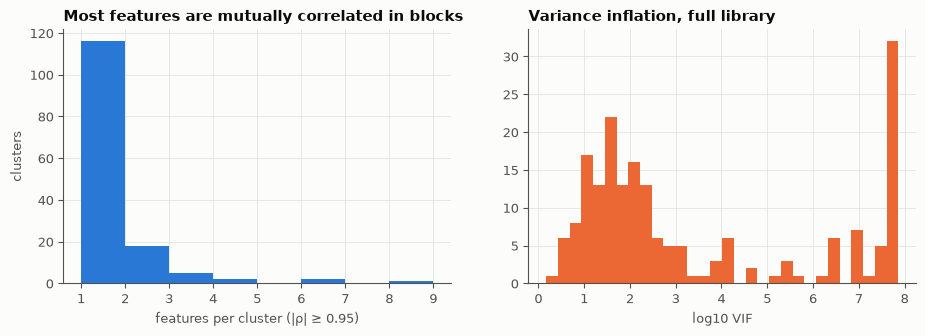

({'n_features': 195,
  'n_clusters': 144,
  'n_multi_feature_clusters': 28,
  'largest_cluster': 8},
 {'condition_number_corr_matrix': 2.34001694321398e+21,
  'features_vif_gt_10': 178,
  'features_vif_gt_100': 112,
  'n': 195})

In [8]:
clu = q.clusters(Xtr, 0.95).merge(man[["feature", "family"]], on="feature")
clu.sort_values(["cluster"]).to_csv(TAB / "correlation_clusters_0.95.csv", index=False)
size = clu.groupby("cluster").feature.size()
S["clusters_abs_corr_ge_0.95"] = {"n_features": int(len(clu)), "n_clusters": int(size.size), "n_multi_feature_clusters": int((size > 1).sum()),
                                  "largest_cluster": int(size.max())}
v = q.vif(Xtr); v.to_csv(TAB / "vif_full_library_fold2022_h3.csv")
S["collinearity"] = {"condition_number_corr_matrix": q.condition_number(Xtr), "features_vif_gt_10": int((v > 10).sum()), "features_vif_gt_100": int((v > 100).sum()), "n": int(len(v))}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(size.values, bins=range(1, int(size.max()) + 2), color=SERIES[0]); ax[0].set_xlabel("features per cluster (|ρ| ≥ 0.95)"); ax[0].set_ylabel("clusters")
ax[0].set_title("Most features are mutually correlated in blocks")
ax[1].hist(np.log10(v.clip(lower=1)), bins=30, color=SERIES[1]); ax[1].set_xlabel("log10 VIF"); ax[1].set_title("Variance inflation, full library")
save(fig, "03_correlation_clusters_vif")
S["clusters_abs_corr_ge_0.95"], S["collinearity"]

Collinearity is expected (rolling sums, lags and EWMs of one series). Correlated features are **not** removed globally: tree models can use them and ridge regression handles them. Selection is model-specific in notebook 06.

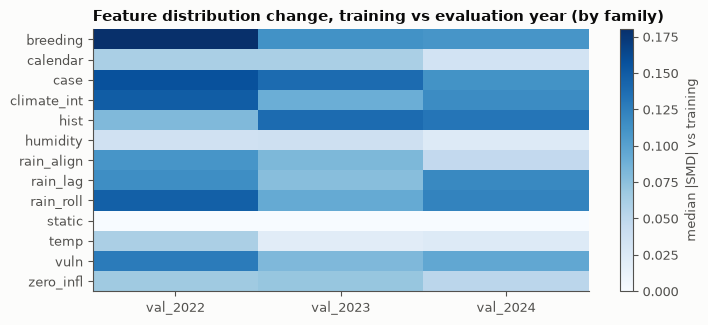

median_abs_smd                   max_abs_smd                   median_ks                  
fold              val_2022 val_2023 val_2024    val_2022 val_2023 val_2024  val_2022 val_2023 val_2024
family                                                                                                
breeding              0.18     0.11     0.11        0.20     0.12     0.15      0.08     0.05     0.06
calendar              0.06     0.06     0.03        0.10     0.08     0.05      0.05     0.04     0.05
case                  0.16     0.14     0.11        0.26     0.20     0.20      0.07     0.05     0.05
climate_int           0.15     0.09     0.12        0.20     0.12     0.13      0.10     0.08     0.08
hist                  0.08     0.14     0.13        0.48     0.66     0.32      0.12     0.13     0.11
humidity              0.04     0.04     0.02        0.11     0.18     0.08      0.04     0.06     0.03
rain_align            0.11     0.08     0.05        0.27     0.14     0.17      0.09     0.06     0.08
rain_lag              0.12     0.08     0.12        0.13     0.08     0.16      0.09     0.06     0.08
rain_roll             0.15     0.09     0.12        0.31     0.30     0.26      0.12     0.08     0.11
static                0.00     0.00     0.00        0.00     0.00     0.00      0.01     0.02     0.01
temp                  0.06     0.02     0.02        0.23     0.33     0.34      0.07     0.07     0.04
vuln                  0.13     0.08     0.10        0.15     0.10     0.13      0.05     0.05     0.05
zero_infl             0.07     0.07     0.05        0.09     0.09     0.13      0.05     0.05     0.06

In [9]:
# distribution shift between training rows and each evaluation year, per fold (h=3)
shift = []
for f in dev_folds():
    d = fold_data(panel, "A_end_of_week", f, 3)
    s = q.year_shift(d.X[d.train.to_numpy()], d.X[d.ev.to_numpy()]).assign(fold=f.name); shift.append(s)
shift = pd.concat(shift).merge(man[["feature", "family"]], on="feature"); shift.to_csv(TAB / "year_shift_h3.csv", index=False)
agg = shift.groupby(["fold", "family"]).agg(median_abs_smd=("smd", lambda s: s.abs().median()), max_abs_smd=("smd", lambda s: s.abs().max()), median_ks=("ks", "median")).round(3)
agg.to_csv(TAB / "year_shift_by_family.csv")
S["year_shift_top"] = shift.assign(a=shift.smd.abs()).sort_values("a", ascending=False).head(8)[["fold", "feature", "smd"]].round(3).to_dict("records")
fig, ax = plt.subplots(figsize=(8, 3.4))
piv = shift.assign(a=shift.smd.abs()).pivot_table(index="family", columns="fold", values="a", aggfunc="median")
im = ax.imshow(piv.values, cmap="Blues", aspect="auto"); ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index)
ax.grid(False); fig.colorbar(im, label="median |SMD| vs training")
ax.set_title("Feature distribution change, training vs evaluation year (by family)")
save(fig, "04_year_shift")
agg.unstack("fold").round(2)

/Volumes/ssd(mac)2/EDU_HACKATHON/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Volumes/ssd(mac)2/EDU_HACKATHON/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Volumes/ssd(mac)2/EDU_HACKATHON/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Volumes/ssd(mac)2/EDU_HACKATHON/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


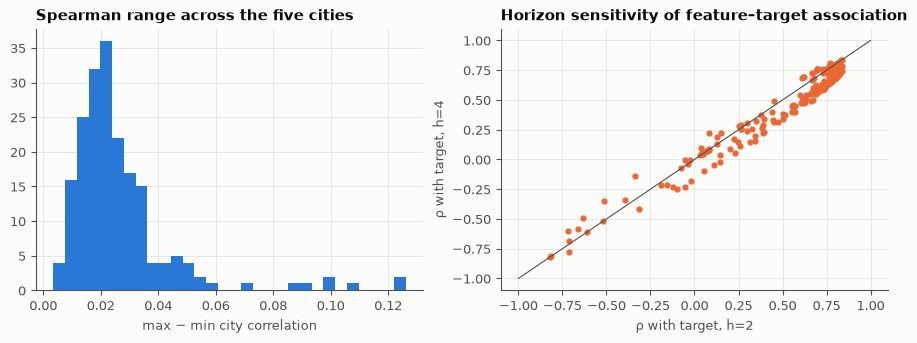

,feature,family,rho_h2,rho_h3,rho_h4
6,cal_org_sin1,calendar,-0.340,-0.241,-0.142
186,case_outbreak_freq8,case,0.346,0.251,0.153
202,zi_pos_frac26,zero_infl,-0.053,-0.145,-0.232
161,case_lag7,case,0.232,0.145,0.057
58,rain_excess4,rain_roll,0.672,0.592,0.500
160,case_lag6,case,0.317,0.232,0.146
178,case_zero_frac12,case,-0.515,-0.432,-0.346
162,case_lag8,case,0.145,0.057,-0.022


In [10]:
# stability across cities and sensitivity to horizon (Spearman with the target, training rows of fold 2022)
cs = q.city_stability(Xtr, ytr, fd.meta.city[tr].to_numpy()).merge(man[["feature", "family"]], on="feature")
hz = {}
for h in (2, 3, 4):
    d = fold_data(panel, "A_end_of_week", fold, h); m = d.train.to_numpy()
    hz[f"rho_h{h}"] = q.target_correlation(d.X[m], d.meta.y_true[m].to_numpy())
hz = pd.DataFrame(hz); hz["rho_range"] = hz.max(axis=1) - hz.min(axis=1); hz = hz.reset_index(names="feature")
cs = cs.merge(hz, on="feature"); cs.to_csv(TAB / "city_and_horizon_stability.csv", index=False)
S["city_stability"] = {"features_with_sign_flip_across_cities": cs[cs.sign_flip].feature.tolist()[:20], "median_city_range": float(cs.city_range.median())}
S["horizon_sensitivity_top"] = cs.sort_values("rho_range", ascending=False).head(10)[["feature", "rho_h2", "rho_h3", "rho_h4"]].round(3).to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(cs.city_range, bins=30, color=SERIES[0]); ax[0].set_title("Spearman range across the five cities"); ax[0].set_xlabel("max − min city correlation")
ax[1].scatter(cs.rho_h2, cs.rho_h4, s=12, color=SERIES[1]); ax[1].plot([-1, 1], [-1, 1], color=INK2, lw=0.8)
ax[1].set_xlabel("ρ with target, h=2"); ax[1].set_ylabel("ρ with target, h=4"); ax[1].set_title("Horizon sensitivity of feature–target association")
save(fig, "05_city_horizon_stability")
cs.sort_values("rho_range", ascending=False).head(8)[["feature", "family", "rho_h2", "rho_h3", "rho_h4"]].round(3)

## 5. Projection quality of the unobserved rainfall (horizon 4: target-lag 3 is observed only after the origin)

In [11]:
rows = []
raw = panel.set_index(["ward_id", "date"]).rainfall_mm
for mode in ("zero", "clim", "regime"):
    for f in dev_folds():
        d = fold_data(panel, "A_end_of_week", f, 4, rain_est=mode)
        e = d.ev.to_numpy(); m = d.meta[e]
        truth = raw.loc[list(zip(m.ward_id, m.origin_date + pd.Timedelta(weeks=1)))].to_numpy()   # rain at target-lag 3 (origin + 1 week); evaluation only
        est = d.X.loc[e, "rain_tl3"].to_numpy()
        ok = ~np.isnan(est)
        rows.append({"mode": mode, "fold": f.name, "rmse_mm": float(np.sqrt(np.mean((est[ok] - truth[ok]) ** 2))), "mae_mm": float(np.mean(np.abs(est[ok] - truth[ok]))),
                     "bias_mm": float(np.mean(est[ok] - truth[ok])), "n": int(ok.sum())})
proj = pd.DataFrame(rows); proj.to_csv(TAB / "rain_projection_accuracy_h4.csv", index=False)
S["rain_projection_accuracy_h4_mean"] = proj.groupby("mode")[["rmse_mm", "mae_mm", "bias_mm"]].mean().round(2).to_dict("index")
proj.groupby("mode")[["rmse_mm", "mae_mm", "bias_mm"]].mean().round(2)

,rmse_mm,mae_mm,bias_mm
mode,,,
clim,34.05,20.86,-0.12
regime,37.43,24.23,3.69
zero,64.91,38.71,-38.71


The projection accuracy is evaluated against the later-observed rain **for reporting only**; this comparison does not feed any model. Downstream effect on MAE is in notebook 05.

## 6. Runtime and memory of feature construction

In [12]:
rt = []
for conv in ("A_end_of_week", "B_start_of_week"):
    w, c = CONVENTIONS[conv]
    pipe = FeaturePipeline(w, c).fit(panel, "2021-12-31")
    for h in (2, 3, 4):
        t0 = time.perf_counter(); fm = pipe.transform(panel, h); dt = time.perf_counter() - t0
        rt.append({"convention": conv, "horizon": h, "rows": len(fm.X), "features": fm.X.shape[1], "build_seconds": round(dt, 3),
                   "matrix_MB": round(fm.X.memory_usage().sum() / 1e6, 1)})
    one = pipe.transform(panel, 3, origins=[panel.date.max() - pd.Timedelta(weeks=3)])
    t0 = time.perf_counter(); pipe.transform(panel, 3, origins=[panel.date.max() - pd.Timedelta(weeks=3)]); dt = time.perf_counter() - t0
    rt.append({"convention": conv, "horizon": "3 (one origin, all 60 wards)", "rows": len(one.X), "features": one.X.shape[1], "build_seconds": round(dt, 3), "matrix_MB": round(one.X.memory_usage().sum() / 1e6, 3)})
rt = pd.DataFrame(rt); rt.to_csv(TAB / "feature_build_runtime.csv", index=False)
S["peak_rss_MB_notebook"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6, 0)
rt

,convention,horizon,rows,features,build_seconds,matrix_MB
0,A_end_of_week,2,28080,204,0.120,45.800
1,A_end_of_week,3,28020,204,0.126,45.700
2,A_end_of_week,4,27960,204,0.131,45.600
3,A_end_of_week,"3 (one origin, all 60 wards)",60,204,0.120,0.098
4,B_start_of_week,2,28080,204,0.142,45.800
5,B_start_of_week,3,28020,204,0.133,45.700
6,B_start_of_week,4,27960,204,0.141,45.600
7,B_start_of_week,"3 (one origin, all 60 wards)",60,204,0.121,0.098


## 7. Auto-generated feature definitions (`docs/feature_definitions.md`)

In [13]:
LBL = {1: "1", 2: "2", 3: "3", 4: "4"}
lines = ["# Feature definitions (auto-generated by notebooks/04_feature_engineering.ipynb)", "",
         "Availability classes: **1** observed at origin, **2** derived from observed history, **3** known in advance (calendar/static/flags), **4** estimated from past-year climatology, **5** prohibited (never built).",
         "Columns `A h2/h3/h4` give the class under convention A (end of week); `B` under convention B (start of week).", ""]
for fam, g in man.groupby("family", sort=False):
    lines += [f"## {fam} ({len(g)})", "", "| feature | A h2 | A h3 | A h4 | B h2 | B h3 | B h4 | definition |", "|---|---|---|---|---|---|---|---|"]
    for r in g.itertuples():
        lines.append(f"| `{r.feature}` | {r.avail_A_h2} | {r.avail_A_h3} | {r.avail_A_h4} | {r.avail_B_h2} | {r.avail_B_h3} | {r.avail_B_h4} | {r.description} |")
    lines.append("")
(ROOT / "docs" / "feature_definitions.md").write_text("\n".join(lines))
print(len(man), "features documented")

204 features documented


In [14]:
import json
(OUT / "feature_engineering_summary.json").write_text(json.dumps(S, indent=2, default=str))
print(json.dumps({k: S[k] for k in ["n_candidate_features", "date_convention", "duplicates_in_every_setting", "clusters_abs_corr_ge_0.95", "collinearity"]}, indent=1, default=str))

{
 "n_candidate_features": 204,
 "date_convention": {
  "best_offsets_days": [
   1,
   2,
   3
  ],
  "violations_offset0": 10,
  "violations_best": 8
 },
 "duplicates_in_every_setting": [
  "breed_no_wl",
  "breed_rain_only",
  "rain_mean2",
  "rain_mean3",
  "rain_mean4",
  "rain_mean6",
  "rain_mean8",
  "rain_tl2_obs",
  "rain_tl3_obs",
  "rain_tl4_obs",
  "rain_tl5",
  "rain_tl5_obs",
  "rain_win_nobs",
  "rh_tl2_obs",
  "temp_tl6",
  "temp_tl6_obs",
  "temp_tl7_obs",
  "temp_tl8_obs",
  "vuln_wl_x_ewm3"
 ],
 "clusters_abs_corr_ge_0.95": {
  "n_features": 195,
  "n_clusters": 144,
  "n_multi_feature_clusters": 28,
  "largest_cluster": 8
 },
 "collinearity": {
  "condition_number_corr_matrix": 2.34001694321398e+21,
  "features_vif_gt_10": 178,
  "features_vif_gt_100": 112,
  "n": 195
 }
}
